# Libraries

In [1]:
import sys
sys.path.append("../")  # go up one level from notebooks/ to project root (for using src/)
import os
from dotenv import load_dotenv
import json
import requests
from itertools import combinations, chain
import matplotlib.pyplot as plt
import time
import datetime
from collections import Counter
from acl_anthology import Anthology
from datetime import datetime, date

from src.query_builder import build_semantic_scholar_query, load_keywords, keyword_to_regex, build_acl_text_matcher, load_keywords 
from src.data_collection import collect_semantic_scholar_data, load_config, collect_acl_data
from src.utils import venn_from_topics, venn_matrix

In [ ]:
# Run in case you make changes to src/data_collection.py and want to reload it without restarting the notebook kernel

# import importlib
# import src.data_collection

# # 1. Reload the module itself
# importlib.reload(src.data_collection)

# # 2. Re-assign the functions to your local variables
# collect_semantic_scholar_data = src.data_collection.collect_semantic_scholar_data
# load_config = src.data_collection.load_config

In [2]:
# Load API keys from .env file
load_dotenv("../.env")
semantic_scholar_api_key = os.getenv("SEMANTIC_SCHOLAR_API_KEY")

# Semantic Scholar

## Didactic example
Didactic example of how to use the bulk search endpoint. 

Notes on keywords search:

Semantic Scholar is not case sensitive. 
So, unfortunately, keywords like "Signal", the platform, will get us results from "signal", the general word. So we may get an important number of false positives (e.g., from areas like signal processing). 

Wildcards can be used on single words only. For instance "LLM*" works fine, but it does not work with multi-word phrases like "climate action*", in those cases we must specify "climate action" and "climate actions".   

In [4]:
# Semantic Scholar didactic example of how to use the bulk search endpoint

# Define the bulk search endpoint
url = "https://api.semanticscholar.org/graph/v1/paper/search/bulk"

# Set up your query parameters
query_params = {
    "query": '"climate change" AND "social media" AND (misinformation OR polarization)',
    # "year": "2020",
    "publicationDateOrYear": "2020-01-01:2020-12-31", 
    "fields": "paperId,title,year"
    # "fields": "paperId,externalIds,title,year,publicationDate,abstract,publicationVenue,journal,citationCount,s2FieldsOfStudy,publicationTypes,authors"
}

# Optional: Add your API key if you have one to avoid rate limits
headers = {"x-api-key": semantic_scholar_api_key}

try:
    response = requests.get(url, params=query_params, headers=headers)
    response.raise_for_status()

    # Parse and print the JSON response
    data = response.json()
    print(json.dumps(data, indent=2))

except requests.exceptions.HTTPError as err:
    print(f"HTTP Error: {err}")
except Exception as e:
    print(f"An error occurred: {e}")

{
  "total": 2,
  "token": null,
  "data": [
    {
      "paperId": "0978a91dbbfdf0b9762fc572e9f7ff3b73b25add",
      "title": "Partisanship, Impeachment, and the Democratic Primaries: American Political Discourse, January - February 2020",
      "year": 2020
    },
    {
      "paperId": "85f4d04076aefafe60a8ead0435b34bf7d8fbfdd",
      "title": "Online misinformation about climate change",
      "year": 2020
    }
  ]
}


## Extract Semantic Scholar data

These are the main papers that we want to analyse. 
They belong to the following subset:
```climate AND nlp AND social_media AND (misinformation OR polarization)```

In [3]:
# Load configuration
# This includes the fields to search for, and the date range for the search.
config = load_config("../config.yml")

ss_config = config["semantic_scholar"]
date_start = config["search"]["date_start"]
date_end = config["search"]["date_end"]

In [33]:
# Build the query

logic = "climate AND nlp AND social_media AND (misinformation OR polarization)"

semantic_scholar_query = build_semantic_scholar_query(
    logic_string=logic,
    keywords_path="../data/search_query/keywords.yml"
)

print(semantic_scholar_query)
print("\nNumber of characters", len(semantic_scholar_query))
print("Semantic Scholar query length limit is 2000 characters") 

("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation") + ("natural language processing" | NLP | "machine learning" | "LLM*" | AI | "artificial intelligence" | "language model" | "language models" | "neural network" | "neural networks" | GenAI | "Generative AI" | "text mining" | "text processing" | "text classification" | "deep learning" | "transformer*" | "argument mining" | "sentiment analysis") + ("social media" | "social network" | "social networks" | "social platform" | "social platforms" | "online community" | "online communities" | "alternative platform" | "alternative platforms" | alt-tech | Youtube | Rumble | Bitchute | Odysee | Twitch | Quora | Facebook | Instagram | Tiktok | Whatsapp | Telegram | Signal | WeChat | Discord | Threads | Mastodon | Reddit | X | Twitter/X | Twitter |

In [34]:
# Collect data from Semantic Scholar using the bulk search endpoint

collect_semantic_scholar_data(
    query=semantic_scholar_query,
    fields=ss_config["fields_full"],
    output_path=f"../data/raw/semantic_scholar/semantic_scholar_data.jsonl",
    date_start=date_start,
    date_end=date_end,
    api_key=semantic_scholar_api_key
)

Query: ("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation") + ("natural language processing" | NLP | "machine learning" | "LLM*" | AI | "artificial intelligence" | "language model" | "language models" | "neural network" | "neural networks" | GenAI | "Generative AI" | "text mining" | "text processing" | "text classification" | "deep learning" | "transformer*" | "argument mining" | "sentiment analysis") + ("social media" | "social network" | "social networks" | "social platform" | "social platforms" | "online community" | "online communities" | "alternative platform" | "alternative platforms" | alt-tech | Youtube | Rumble | Bitchute | Odysee | Twitch | Quora | Facebook | Instagram | Tiktok | Whatsapp | Telegram | Signal | WeChat | Discord | Threads | Mastodon | Reddit | X | Twitter/X | Tw

(90, 90)

Descriptive analysis of our data. 

Papers with abstracts: 77
Papers without abstracts: 13
Percentage of papers with abstracts: 85.56%
Total papers: 90


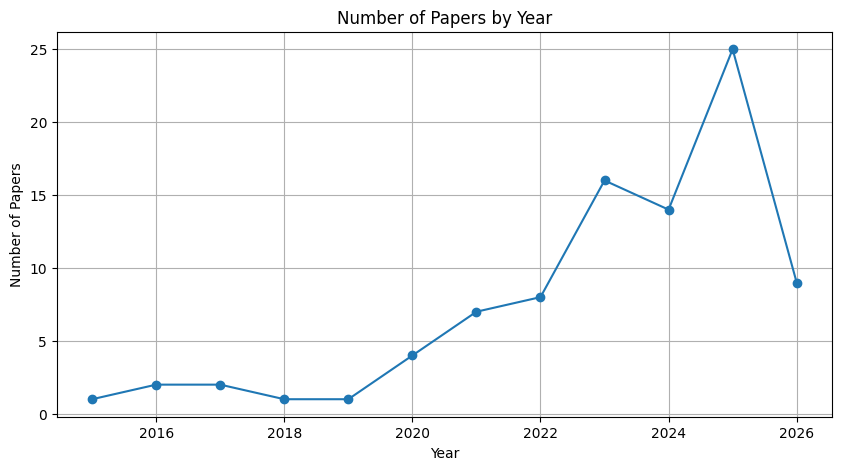

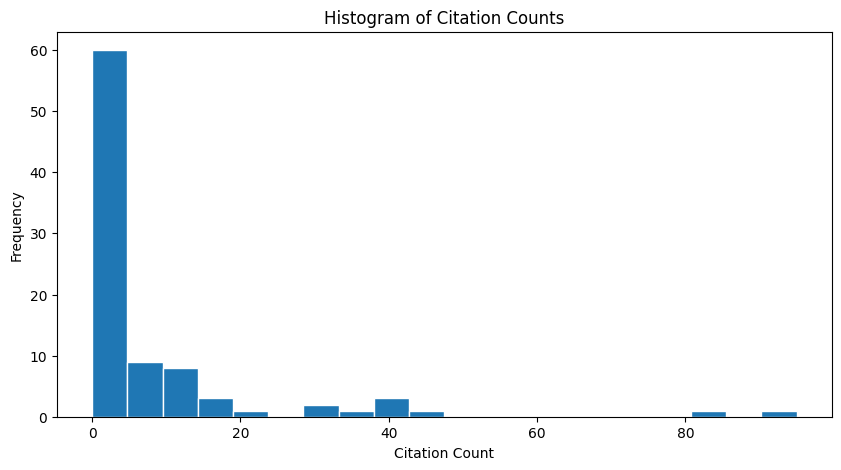

In [35]:
# Check if abstracts were collected successfully
# Load the main dataset and check abstract lengths
abstracts_with_content = 0
abstracts_empty = 0

# Collect years and citation counts
years = []
citation_counts = []

f = open("../data/raw/semantic_scholar/semantic_scholar_data.jsonl", "r")
for line in f:
    paper = json.loads(line)
    abstract = paper.get("abstract", "")
    if abstract and len(abstract) > 0:
        abstracts_with_content += 1
    else:
        abstracts_empty += 1
    
    # Collect year and citation count
    year = paper.get("year")
    if year:
        years.append(year)
    citation_count = paper.get("citationCount")
    if citation_count is not None:
        citation_counts.append(citation_count)

print(f"Papers with abstracts: {abstracts_with_content}")
print(f"Papers without abstracts: {abstracts_empty}")
print(f"Percentage of papers with abstracts: {abstracts_with_content / (abstracts_with_content + abstracts_empty) * 100:.2f}%")
print(f"Total papers: {abstracts_with_content + abstracts_empty}")

# Create a line chart for number of papers by year
year_counts = Counter(years)
sorted_years = sorted(year_counts.keys())
counts = [year_counts[year] for year in sorted_years]

plt.figure(figsize=(10, 5))
plt.plot(sorted_years, counts, marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Number of Papers by Year')
plt.grid(True)
plt.show()

# Create a histogram for citation counts
plt.figure(figsize=(10, 5))
plt.hist(citation_counts, bins=20, edgecolor='white')
plt.xlabel('Citation Count')
plt.ylabel('Frequency')
plt.title('Histogram of Citation Counts')
plt.show()


## Collect data from sets and their intersections

In [36]:
# Uncomment the following code to run the data collection for all combinations of topics. Note that this will take a long time. 

sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]
all_combinations = list(chain.from_iterable(combinations(sets, r) for r in range(1, len(sets) + 1)))

# Dictionary to store the results
intersections_totals = {}

for combination in all_combinations:

    # Logic
    logic = " AND ".join(combination)
    print(f"Retrieving data for: {logic}")

    #Name for the file
    file_name = "_".join(logic.split(" "))
    
    # Build the query
    semantic_scholar_query = build_semantic_scholar_query(
        logic_string=logic,
        keywords_path="../data/search_query/keywords.yml"
    )

    # Extract data
    total_downloaded, grand_total = collect_semantic_scholar_data(
        query=semantic_scholar_query,
        fields=ss_config["fields_lite"],
        output_path=f"../data/raw/semantic_scholar/sets/{file_name}.jsonl", 
        date_start=date_start,
        date_end=date_end,
        api_key=semantic_scholar_api_key
    )

    # Store the total number of results for this combination
    intersections_totals[logic] = {"total_downloaded": total_downloaded, "grand_total": grand_total, "complete": total_downloaded == grand_total}

    sleep_time = 1.1 if semantic_scholar_api_key else 3.5
    time.sleep(sleep_time)  # Sleep to respect rate limits

# Save the totals to a JSON file
with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "w") as f:
    json.dump(intersections_totals, f, indent=2)

Retrieving data for: climate
Query: ("global warming" | "climate change" | "climate science" | "climate denial" | "climate crisis" | "climate skeptic" | "climate skepticism" | "climate skeptics" | "climate skepticist" | "climate action" | "climate misinformation" | "climate disinformation")
Output: ../data/raw/semantic_scholar/sets/climate.jsonl
API key: yes | Sleep: 1.1s
Fetching batch | total so far: 0
Total papers to retrieve: 702440
Fetching batch | total so far: 1000
Fetching batch | total so far: 2000
Fetching batch | total so far: 3000
Fetching batch | total so far: 4000
HTTP error (429) [attempt 1/5]
Rate limit hit — sleeping 90s
Fetching batch | total so far: 4000
Fetching batch | total so far: 5000
Fetching batch | total so far: 6000
HTTP error (429) [attempt 1/5]
Rate limit hit — sleeping 90s
Fetching batch | total so far: 6000
Fetching batch | total so far: 7000
Fetching batch | total so far: 8000
Fetching batch | total so far: 9000
Fetching batch | total so far: 10000
Fetc

In [4]:
#Load the totals from the JSON file
with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "r") as f:
    intersections_totals = json.load(f)

In [5]:
# See the incomplete downloads 
for logic in intersections_totals:
    if not(intersections_totals[logic]["complete"]):
        print(logic, intersections_totals[logic])

print(f"\n")

# See VERY incomplete downloads (they are not just missing a few papers, they are missing more than x% of the papers that should be retrieved)
error_accepted = 0.03
for logic in intersections_totals:
    if intersections_totals[logic]["grand_total"]:
        threshold = intersections_totals[logic]["grand_total"] - intersections_totals[logic]["grand_total"] * 0.03
        if intersections_totals[logic]["total_downloaded"] < threshold:
            print(logic, intersections_totals[logic])
    else:
        print(logic, intersections_totals[logic])

climate {'total_downloaded': 144978, 'grand_total': 702487, 'complete': False}
nlp {'total_downloaded': 181882, 'grand_total': 3279580, 'complete': False}
social_media {'total_downloaded': 411925, 'grand_total': 7003936, 'complete': False}
polarization {'total_downloaded': 455529, 'grand_total': 455530, 'complete': False}
nlp AND social_media {'total_downloaded': 335949, 'grand_total': 361249, 'complete': False}
social_media AND polarization {'total_downloaded': 98179, 'grand_total': 98180, 'complete': False}


climate {'total_downloaded': 144978, 'grand_total': 702487, 'complete': False}
nlp {'total_downloaded': 181882, 'grand_total': 3279580, 'complete': False}
social_media {'total_downloaded': 411925, 'grand_total': 7003936, 'complete': False}
nlp AND social_media {'total_downloaded': 335949, 'grand_total': 361249, 'complete': False}


In [ ]:
# Semi manual recovery
# Remove this section later.

logics_to_repeat = ["polarization", "nlp AND social_media", "nlp"]

for logic in logics_to_repeat:

    # Logic
    print(f"Retrieving data for: {logic}")

    #Name for the file
    file_name = "_".join(logic.split(" "))
    
    # Build the query
    semantic_scholar_query = build_semantic_scholar_query(
        logic_string=logic,
        keywords_path="../data/search_query/keywords.yml"
    )

    # Extract data
    total_downloaded, grand_total = collect_semantic_scholar_data(
        query=semantic_scholar_query,
        fields=ss_config["fields_lite"],
        output_path=f"../data/raw/semantic_scholar/sets/{file_name}.jsonl", 
        date_start=date_start,
        date_end=date_end,
        api_key=semantic_scholar_api_key
    )

    # Store the total number of results for this combination
    intersections_totals[logic] = {"total_downloaded": total_downloaded, "grand_total": grand_total, "complete": total_downloaded == grand_total}

    sleep_time = 1.1 if semantic_scholar_api_key else 3.5
    time.sleep(sleep_time)  # Sleep to respect rate limits

    # Save the totals to a JSON file
    with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "w") as f:
        json.dump(intersections_totals, f, indent=2)

Retrieving data for: misinformation
Query: ("misinform*" | "disinform*" | "fake news" | "conspiracy theory" | "conspiracy theories" | debunking | "claim verification" | deception | "hoax*" | "fallac*" | "rumor*" | "malinformat*" | propaganda)
Output: ../data/raw/semantic_scholar/sets/misinformation.jsonl
API key: yes | Sleep: 1.1s
Fetching batch | total so far: 0
Total papers to retrieve: 166628
Fetching batch | total so far: 1000
Fetching batch | total so far: 2000
Fetching batch | total so far: 3000
Fetching batch | total so far: 4000
Fetching batch | total so far: 5000
Fetching batch | total so far: 6000
Fetching batch | total so far: 7000
HTTP error (429) [attempt 1/5]
Rate limit hit — sleeping 90s
Fetching batch | total so far: 7000
Fetching batch | total so far: 8000
Fetching batch | total so far: 9000
Fetching batch | total so far: 10000
Fetching batch | total so far: 11000
Fetching batch | total so far: 12000
Fetching batch | total so far: 13000
Fetching batch | total so far: 1

In some cases the mismatch between total_downloaded and grand_total is minimal (e.g., 99 downloaded vs 100 total), which suggests that the download process was mostly successful. In this cases the API does not return any error.

The data collection for social_media is problematic given to the size of the data to be retrieved. The API stops the pagination process (it does not provide a further pagination token) without providing any other error or warning. We break the data collection for this one into batches by year as follows. 

We store the data by year in a temporal directory. Then we unify the results.

In [ ]:
# Collect social_media data in batches by year. 
logic = "social_media"
logic_name = "_".join(logic.split(" ")) 

# Build the query
semantic_scholar_query = build_semantic_scholar_query(
    logic_string=logic,
    keywords_path="../data/search_query/keywords.yml"
)

# Temporal directory
temporal_dir = "../data/raw/semantic_scholar/sets/tmp/"

# Error accepted
# Repeat the download for the year until we are within x% of the total number of results for that year.
error_accepted = 0.03  # 3%

# List to store years that are already complete so that we can skip them
complete_years = []
# Check if there is a batch_totals.json
if os.path.exists(f"{temporal_dir}{logic_name}/batch_totals.json"):
    with open(f"{temporal_dir}{logic_name}/batch_totals.json", "r") as f:
        batch_totals = json.load(f)

    # Collect years that are already complete so that we can skip them in the next step
    error_accepted = 0.03
    for year in batch_totals:
        if batch_totals[year]["grand_total"]:
            threshold = batch_totals[year]["grand_total"] - batch_totals[year]["grand_total"] * 0.03
            if batch_totals[year]["total_downloaded"] > threshold:
                complete_years.append(int(year))
else:
    # In case there is no existing batch_totals.json, initialize it
    batch_totals = {}

# Download data in batches by calendar year. Saves each batch in a separate file.
# For instance, if the date range is 01/05/2010 to 31/08/2020, it will download data for 2010 (from 01/05 to 31/12), then for 2011, then for 2012, ..., and finally for 2020 (from 01/01 to 31/08).
# Assuming date_start and date_end are already defined as datetime.date objects
for year in range(date_start.year, date_end.year + 1):

    # skip years with good enough results already
    if year in complete_years:
        continue

    # Repeat the download for the year until we are within the accepted error threshold of the total number of results for that year.
    total_downloaded_in_batch = 0
    accepted_threshold = 10000 # some big number to enter the loop for the first time

    while total_downloaded_in_batch < accepted_threshold :

        d_start = max(date_start, date(year, 1, 1))
        d_end = min(date_end, date(year, 12, 31))
        print(f"Period: {d_start} to {d_end}")

        #Name for the file
        file_name = logic_name + f"_{year}"

        # Extract data
        total_downloaded_in_batch, grand_total_in_batch = collect_semantic_scholar_data(
            query=semantic_scholar_query,
            fields=ss_config["fields_lite"],
            output_path=f"{temporal_dir}{logic_name}/{file_name}.jsonl", 
            date_start=d_start,
            date_end=d_end,
            api_key=semantic_scholar_api_key
        )
        
        batch_totals[year] = {"total_downloaded": total_downloaded_in_batch, "grand_total": grand_total_in_batch, "complete": total_downloaded_in_batch == grand_total_in_batch}

        accepted_threshold = grand_total_in_batch - grand_total_in_batch * error_accepted # accept if we are within the accepted error threshold

        # Save the totals to a JSON file
        with open(f"{temporal_dir}{logic_name}/batch_totals.json", "w") as f:
            json.dump(batch_totals, f, indent=2)

        sleep_time = 1.1 if semantic_scholar_api_key else 3.5
        time.sleep(sleep_time)  # Sleep to respect rate limits   

Period: 2012-01-01 to 2012-12-31
Query: ("social media" | "social network" | "social networks" | "social platform" | "social platforms" | "online community" | "online communities" | "alternative platform" | "alternative platforms" | alt-tech | Youtube | Rumble | Bitchute | Odysee | Twitch | Quora | Facebook | Instagram | Tiktok | Whatsapp | Telegram | Signal | WeChat | Discord | Threads | Mastodon | Reddit | X | Twitter/X | Twitter | Bluesky | 4chan | 8kun | 8chan | Parler | Gab | "Truth Social" | MeWe | Snapchat | LinkedIn | tweet | tweets | "user comment" | "user comments")
Output: ../data/raw/semantic_scholar/sets/tmp/social_media/social_media_2012.jsonl
API key: yes | Sleep: 1.1s
Fetching batch | total so far: 0
Total papers to retrieve: 413689
Fetching batch | total so far: 1000
Fetching batch | total so far: 2000
Fetching batch | total so far: 3000
HTTP error (429) [attempt 1/5]
Rate limit hit — sleeping 90s
Fetching batch | total so far: 3000
Fetching batch | total so far: 4000


In [ ]:
# See the incomplete downloads. If nothing is printed, it means all batches were downloaded successfully.
for batch in batch_totals:
    if not(batch_totals[batch]["complete"]):
        print(batch, batch_totals[batch])

In [9]:
# Unify the yearly .jsonl files into a single .jsonl file. 
# Same for the metadata .json files. The unified metadata will also include a breakdown of totals and errors by year, in case some years had issues while others didn't.
output_dir = "../data/raw/semantic_scholar/sets/"

unified_jsonl_path = f"{output_dir}{logic_name}.jsonl"
unified_meta_path  = f"{output_dir}{logic_name}_meta.json"

# Unify .jsonl files 
with open(unified_jsonl_path, "w", encoding="utf-8") as out_f:
    for year in range(date_start.year, date_end.year + 1):
        file_name   = logic_name + f"_{year}"
        jsonl_path  = f"{temporal_dir}{logic_name}/{file_name}.jsonl"

        # if not jsonl_path.exists():
        #     print(f"[WARN] Missing data file: {jsonl_path}")
        #     continue

        with open(jsonl_path, encoding="utf-8") as in_f:
            for line in in_f:
                line = line.rstrip("\n")
                if line:                        # skip blank lines
                    out_f.write(line + "\n")

print(f"Unified JSONL saved → {unified_jsonl_path}")

# Unify metadata .json files
unified_meta = {
    "timestamp":        datetime.datetime.now().isoformat(),
    "query":            None,
    "fields":           None,
    "date_start":       str(date_start),
    "date_end":         str(date_end),
    "api_key_used":     None,
    "total_downloaded": 0,
    "grand_total":      0,
    "error":            None,
    "per_year":         {}          # optional: keep each year's counts
}

for year in range(date_start.year, date_end.year + 1):
    file_name  = logic_name + f"_{year}"
    meta_path  = f"{temporal_dir}{logic_name}/{file_name}_meta.json"

    # if not meta_path.exists():
    #     print(f"[WARN] Missing metadata file: {meta_path}")
    #     continue

    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)

    # Shared fields – set on first encounter, warn if they differ later
    for shared_key in ("query", "fields", "api_key_used"):
        if unified_meta[shared_key] is None:
            unified_meta[shared_key] = meta.get(shared_key)
        elif unified_meta[shared_key] != meta.get(shared_key):
            print(f"[WARN] '{shared_key}' differs in {year}: {meta.get(shared_key)}")

    # Accumulate counts
    unified_meta["total_downloaded"] += meta.get("total_downloaded", 0)
    unified_meta["grand_total"]      += meta.get("grand_total", 0)

    # Collect per-year errors (skip None)
    if meta.get("error") is not None:
        unified_meta["error"] = unified_meta.get("error") or {}
        unified_meta["error"][str(year)] = meta["error"]

    # Store per-year breakdown
    unified_meta["per_year"][str(year)] = {
        "total_downloaded": meta.get("total_downloaded", 0),
        "grand_total":      meta.get("grand_total", 0),
        "date_start":       meta.get("date_start"),
        "date_end":         meta.get("date_end"),
    }

with open(unified_meta_path, "w", encoding="utf-8") as f:
    json.dump(unified_meta, f, indent=2, ensure_ascii=False)

print(f"Unified metadata saved → {unified_meta_path}")

# Store the total number of results for this combination
intersections_totals[logic] = {"total_downloaded": unified_meta["total_downloaded"], "grand_total": unified_meta["grand_total"], "complete": unified_meta["total_downloaded"] == unified_meta["grand_total"]}

# Save the totals to a JSON file
with open("../data/raw/semantic_scholar/sets/intersections_totals.json", "w") as f:
    json.dump(intersections_totals, f, indent=2)


Unified JSONL saved → ../data/raw/semantic_scholar/sets/social_media.jsonl
Unified metadata saved → ../data/raw/semantic_scholar/sets/social_media_meta.json


In [10]:
# See the incomplete downloads
for logic in intersections_totals:
    if not(intersections_totals[logic]["complete"]):
        print(logic, intersections_totals[logic])

climate {'total_downloaded': 702261, 'grand_total': 702270, 'complete': False}
nlp {'total_downloaded': 3272542, 'grand_total': 3272587, 'complete': False}
social_media {'total_downloaded': 9893708, 'grand_total': 9990057, 'complete': False}
polarization {'total_downloaded': 455684, 'grand_total': 455687, 'complete': False}
nlp AND social_media {'total_downloaded': 426246, 'grand_total': 426253, 'complete': False}
nlp AND polarization {'total_downloaded': 8550, 'grand_total': 8551, 'complete': False}
social_media AND polarization {'total_downloaded': 104831, 'grand_total': 104832, 'complete': False}


## Descriptives about the intersections

In [16]:
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]

# Colors for each set
colors = {
    "climate": "green",
    "nlp": "blue",
    "social_media": "yellow",
    "misinformation": "red",
    "polarization": "gray"
}

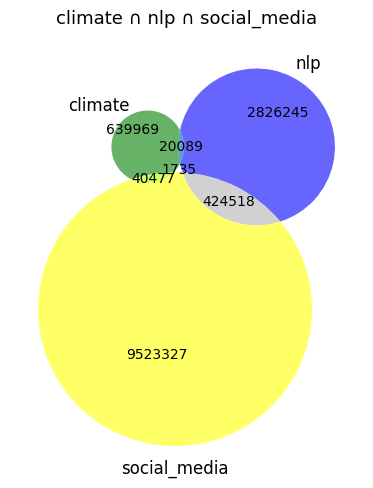

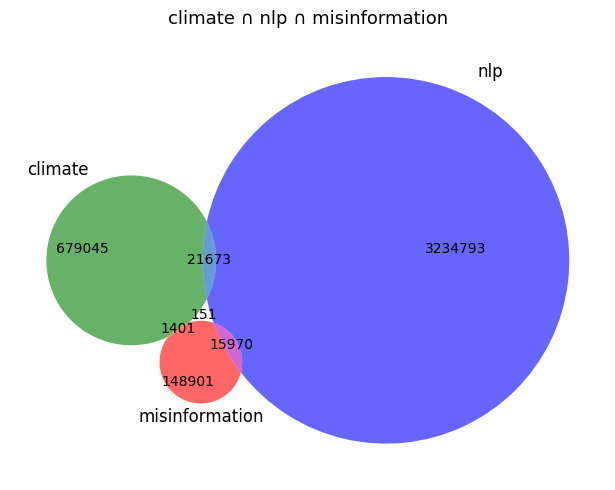

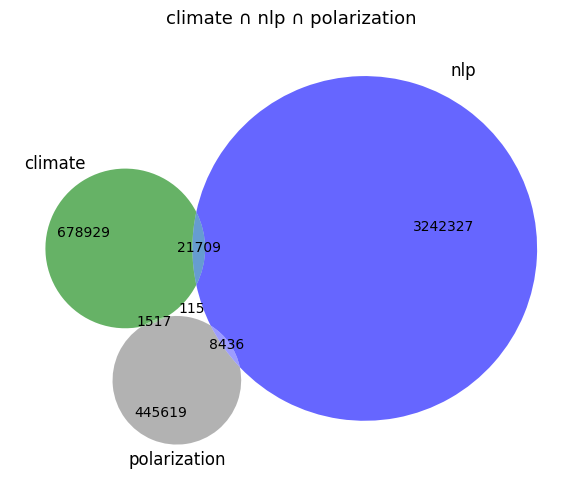

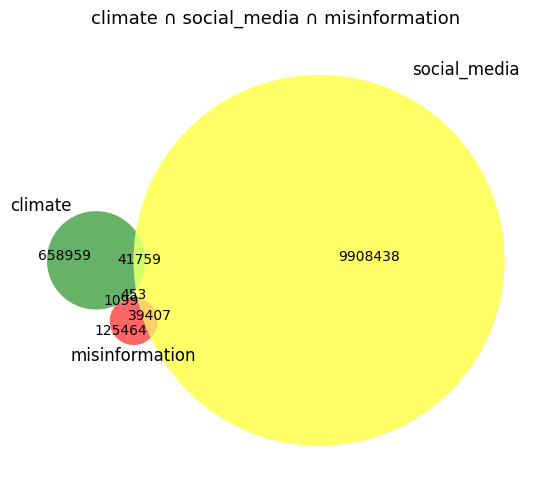

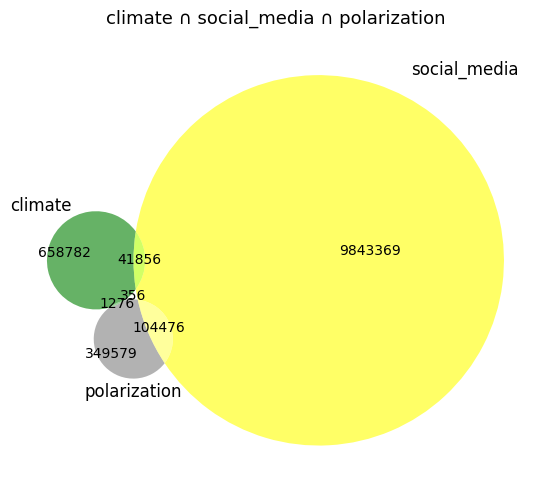

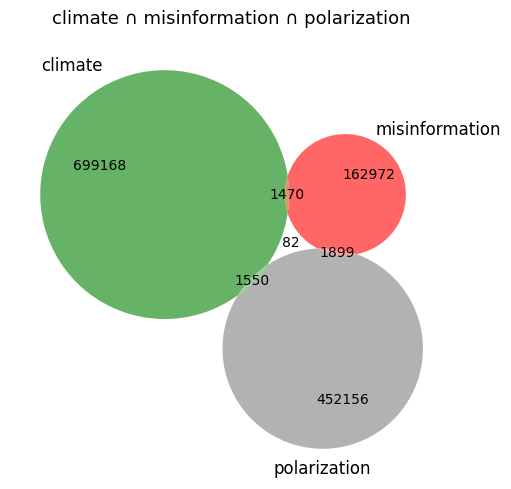

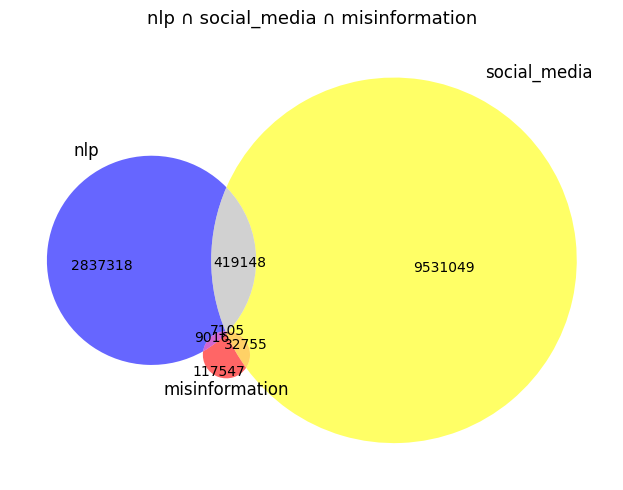

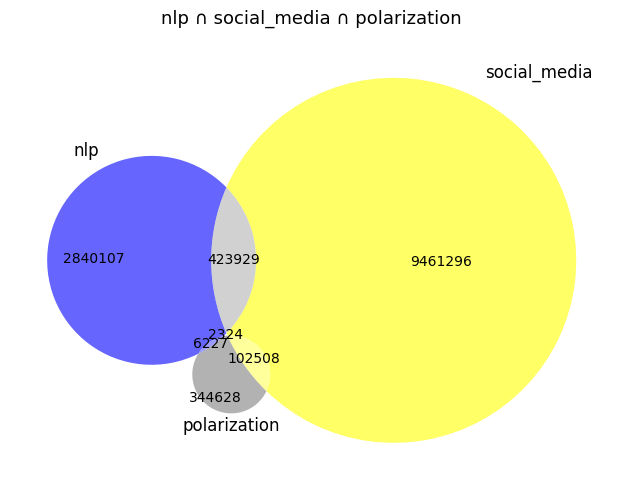

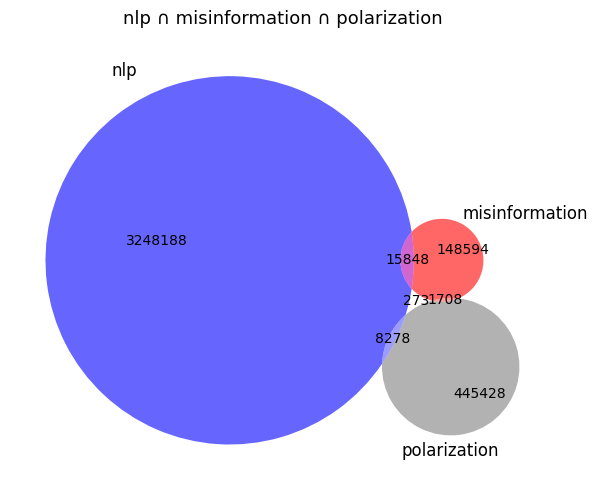

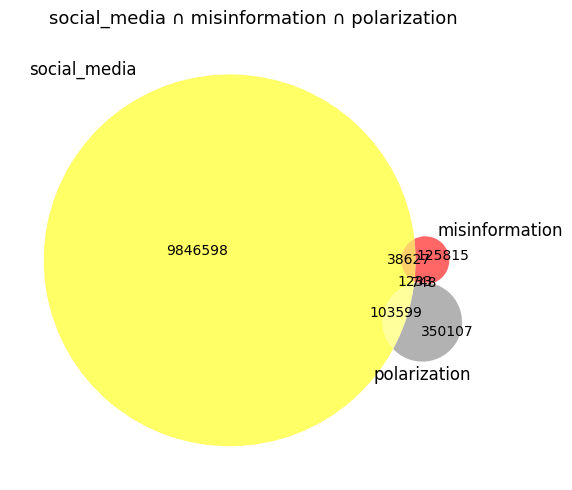

In [12]:
# Get all combinations of 3 sets
combinations_of_3_sets = list(combinations(sets, 3))

# Draw Venn diagrams for all combinations of 3 sets
for sets in combinations_of_3_sets:
    venn_from_topics(
        topics=sets,
        colors=colors,
        sizes={topic: intersections_totals[topic]["grand_total"] for topic in intersections_totals}
    )

(<Figure size 1800x2000 with 20 Axes>,
 array([[<Axes: title={'center': 'climate ∩ nlp'}>,
         <Axes: title={'center': 'climate ∩ social_media'}>,
         <Axes: title={'center': 'climate ∩ misinformation'}>,
         <Axes: title={'center': 'climate ∩ polarization'}>],
        [<Axes: >, <Axes: title={'center': 'nlp ∩ social_media'}>,
         <Axes: title={'center': 'nlp ∩ misinformation'}>,
         <Axes: title={'center': 'nlp ∩ polarization'}>],
        [<Axes: >, <Axes: >,
         <Axes: title={'center': 'social_media ∩ misinformation'}>,
         <Axes: title={'center': 'social_media ∩ polarization'}>],
        [<Axes: >, <Axes: >, <Axes: >,
         <Axes: title={'center': 'misinformation ∩ polarization'}>],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

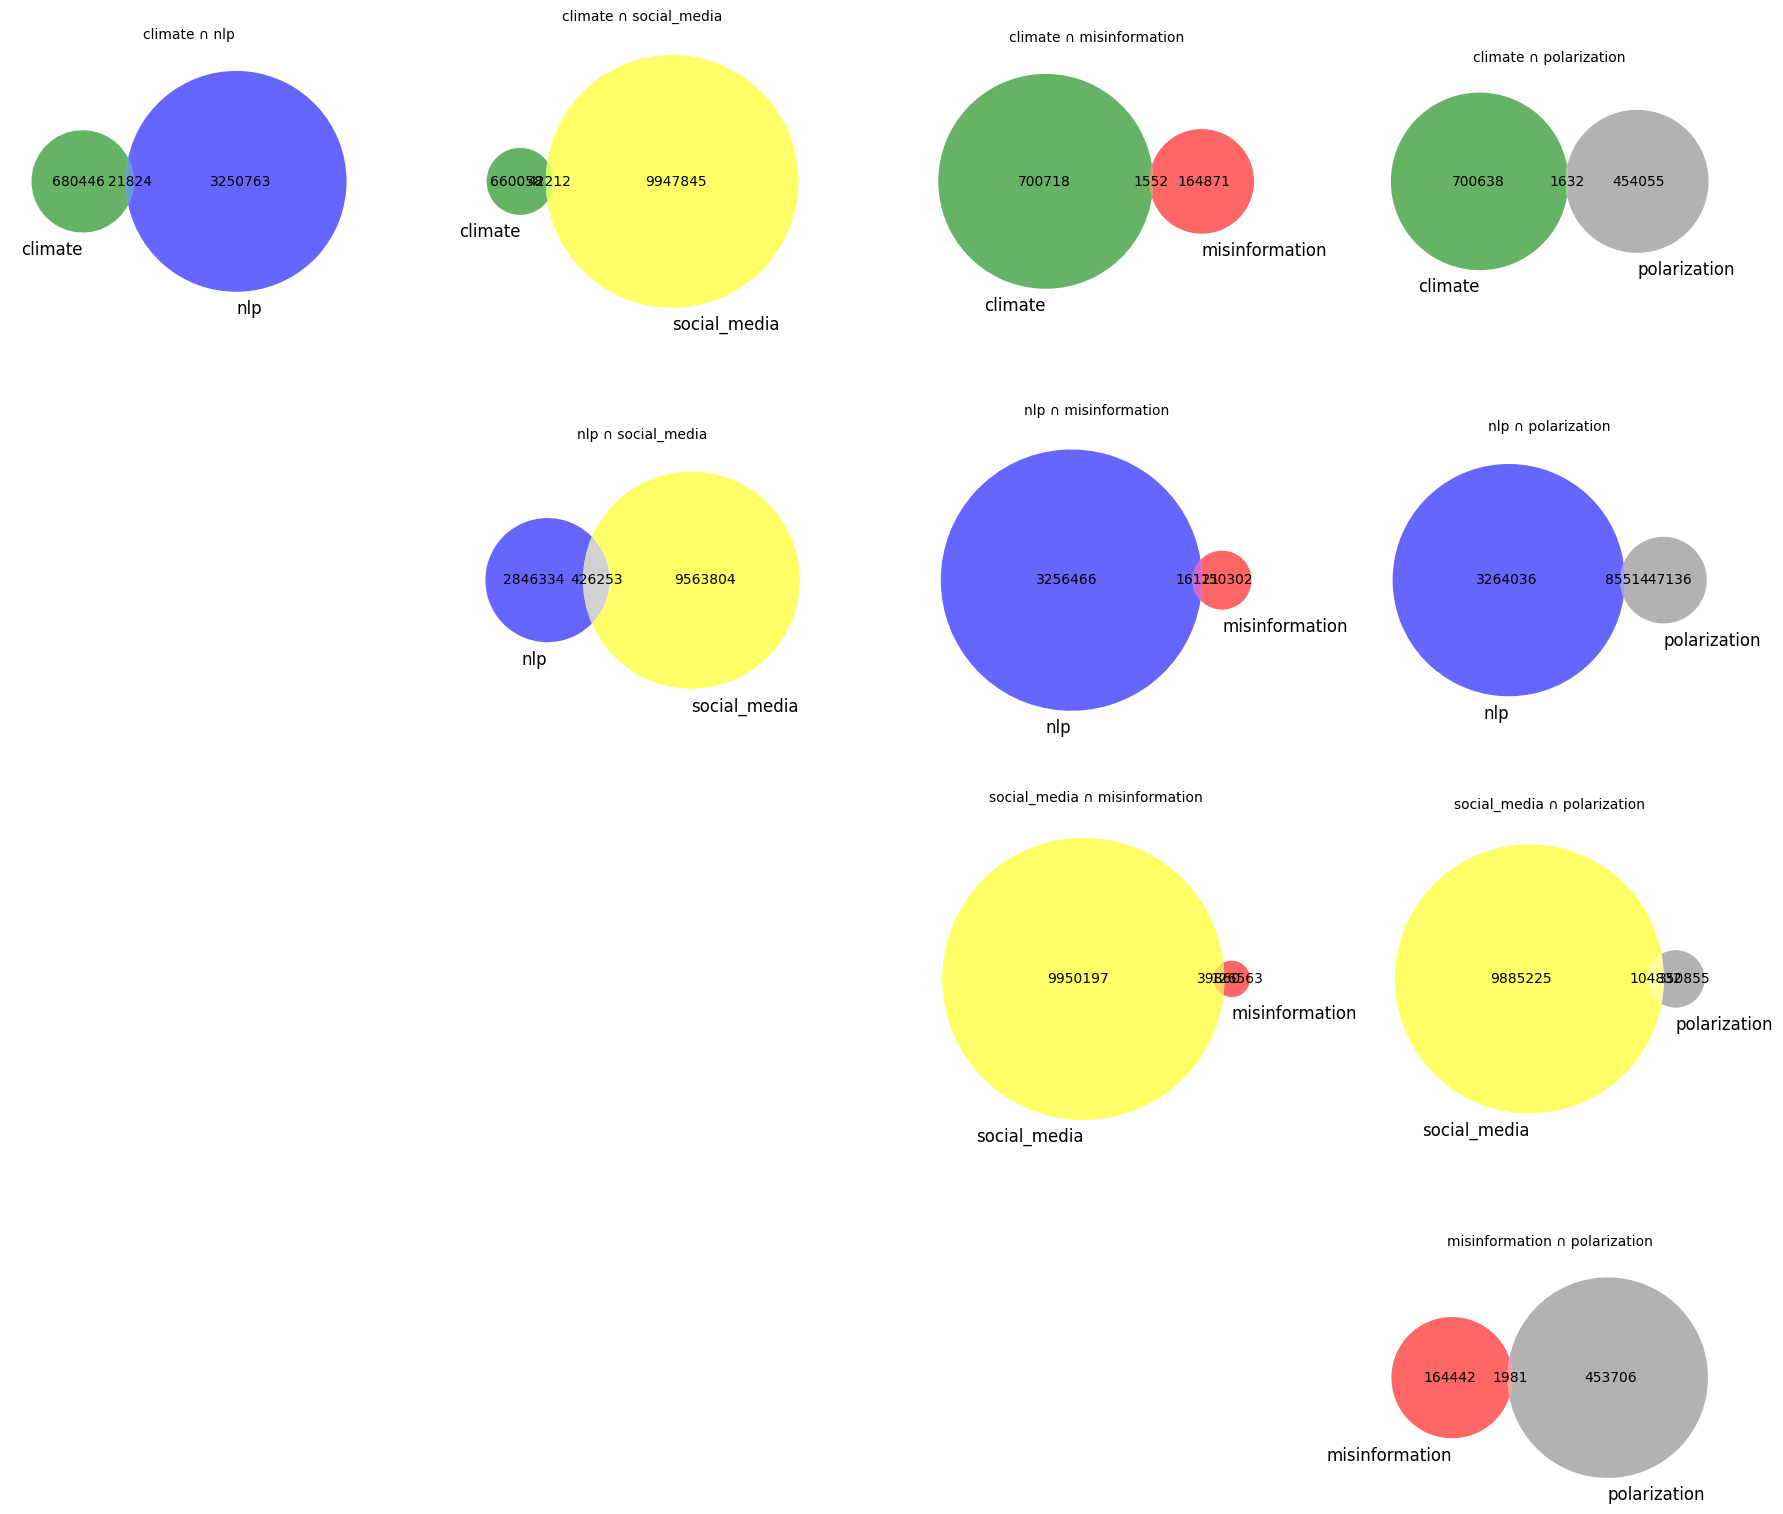

In [17]:
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]

venn_matrix(
    topics=sets,
    colors=colors,
    sizes={topic: intersections_totals[topic]["grand_total"] for topic in intersections_totals}
)

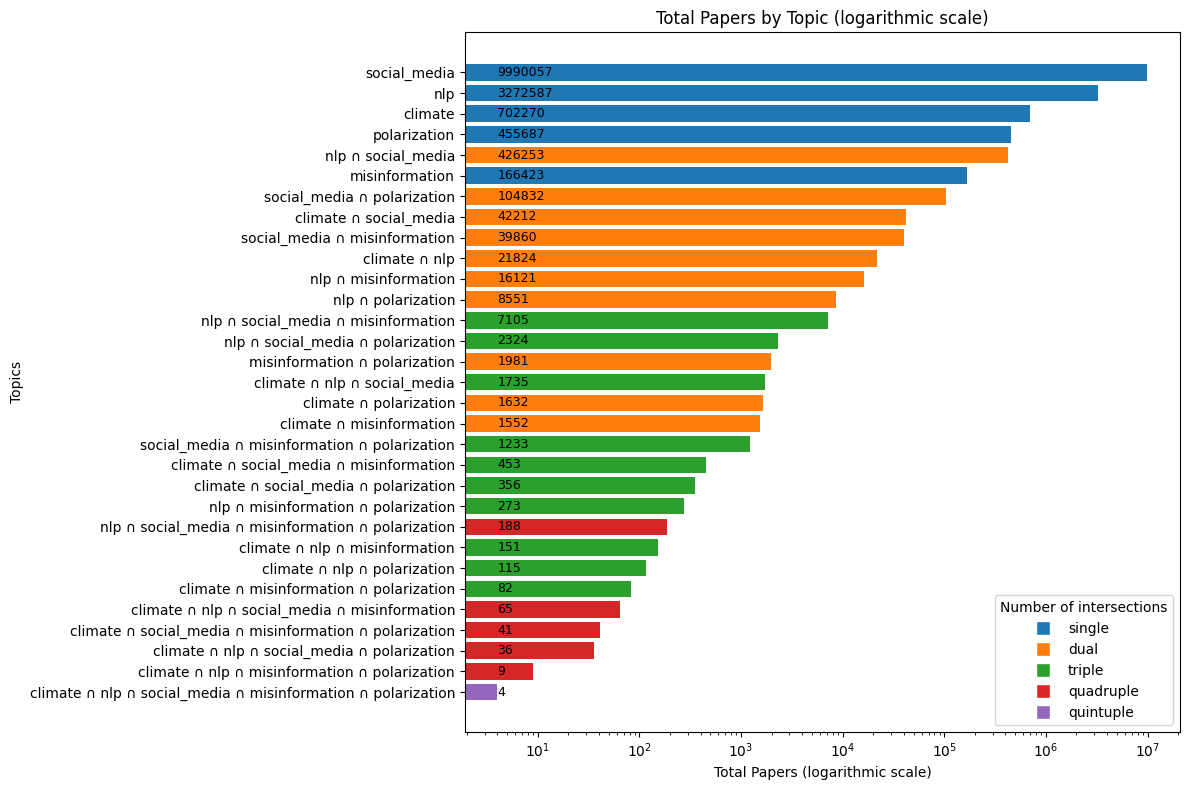

In [14]:
# See totals for each topic and their intersections

topics = list(intersections_totals.keys())
grand_totals = [intersections_totals[topic]['grand_total'] for topic in topics]

# Sort by grand_total ascending for better readability
sorted_indices = sorted(range(len(grand_totals)), key=lambda i: grand_totals[i], reverse=False)
topics_sorted = [topics[i] for i in sorted_indices]
grand_totals_sorted = [grand_totals[i] for i in sorted_indices]

# Map number of ANDs to label and color
level_labels = {
    0: "single",
    1: "dual",
    2: "triple",
    3: "quadruple",
    4: "quintuple",
}
color_map = {
    "single": "tab:blue",
    "dual": "tab:orange",
    "triple": "tab:green",
    "quadruple": "tab:red",
    "quintuple": "tab:purple",
}

bar_colors = []
for topic in topics_sorted:
    n_and = topic.count(" AND ")
    level = level_labels.get(n_and, f"{n_and+1}-set")
    bar_colors.append(color_map.get(level, "tab:gray"))

# Replace "AND" with intersection symbol
topics_sorted = [topic.replace(" AND ", " ∩ ") for topic in topics_sorted]

plt.figure(figsize=(12, 8))
bars = plt.barh(topics_sorted, grand_totals_sorted, color=bar_colors)
plt.xlabel('Total Papers (logarithmic scale)')
plt.ylabel('Topics')
plt.title('Total Papers by Topic (logarithmic scale)')
plt.xscale('log')

# Add grand total numbers on the bars
for i, bar in enumerate(bars):
    plt.text(min(grand_totals), bar.get_y() + bar.get_height() / 2,
             f'{grand_totals_sorted[i]}', va='center', fontsize=9)

# Add a legend for the bar color mapping
legend_handles = [
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=color, markersize=10, label=label)
    for label, color in color_map.items()
]
plt.legend(handles=legend_handles, title="Number of intersections", loc='lower right')

plt.tight_layout()
plt.show()

# ACL

In [66]:
anthology = Anthology.from_repo()

In [5]:
# Run in case you make changes to src/data_collection.py and want to reload it without restarting the notebook kernel

import importlib
import src.data_collection
import src.query_builder

# 1. Reload the module itself
importlib.reload(src.data_collection)
importlib.reload(src.query_builder)

# 2. Re-assign the functions to your local variables
collect_acl_data = src.data_collection.collect_acl_data
build_acl_text_matcher = src.query_builder.build_acl_text_matcher

## Didactic examples

The ACL anthology does not include a date of publication. The month variable is also hard to use because it has create variability, providing responses like "October 29 – November 1", "September 18-22", "7", and others. Therefore we will rely only on the year of publication. 

In [ ]:
# Example of months. 
for paper in anthology.papers():
    if "nlp" in str(paper.title).lower():
        print(paper.month)

October 29 – November 1
November 20-22
September 18-22
June
April
April
October 24-25
November 27-28
November 27-28
None
None
October 21-25
None
July
May 30–31
June
June
None
None
October 30 – November 3
7
7
None
None
None
6
None
None
None
May
May
May
May
December
December
December
None
None
November
November
November
November
7
11--12 September
11--12 September
None
None
December
December
December
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
July
October
July
November
November
November
March
March
March
March
November
December
December
December
December
December
December
December
December
November
July
November
November
November
November
November
November
November
October
October
October
November
November
November
November
November
November
November
November
November
November
November
November
December
December
December
December
May
May
May
May
May
December
December
DECEMBER
December
November
May
May
July
6
December
December
May
May
Ma

Example of how to filter using a specific keyword and years. 
Notice we use both title and abstract for the filtering. 
In this example the search is case sensitive, contrary to Semantic Scholar where it is impossible to have case sensitivity. 
In fact, the keyword search here is very flexible because we can use regular expresions. Regular expresions are not used in the following example, but they are implemented in the `build_acl_text_matcher` function in `query_builder.py`.  

In [96]:
query = "NLP"
date_start = date(2021, 2, 1)
date_end = date(2021, 3, 1)

start_year = date_start.year
end_year = date_end.year

for paper in anthology.papers():

    # Filter by year first
    if start_year <= int(paper.year) <= end_year:
        # Filter by keywords in title and abstract
        text = paper.title.as_text() + (" " + paper.abstract.as_text() if paper.abstract else "")
        if query in text:
            # paper information
            print(paper)
            # Venue information is not directly in the Paper object.
            print(paper.parent)


Paper(full_id='2021.acl-long.2', bibkey='shani-etal-2021-get', title=MarkupText('<fixed-case>H</fixed-case>ow Did This Get Funded?! <fixed-case>A</fixed-case>utomatically Identifying Quirky Scientific Achievements'), authors=(NameSpecification(Name('Chen', 'Shani')), NameSpecification(Name('Nadav', 'Borenstein')), NameSpecification(Name('Dafna', 'Shahaf'))), videos=(VideoReference(name='2021.acl-long.2.mp4', checksum=None, permission=True),), abstract='Humor is an important social phenomenon, serving complex social and psychological functions. However, despite being studied for millennia humor is computationally not well understood, often considered an AI-complete problem. In this work, we introduce a novel setting in humor mining: automatically detecting funny and unusual scientific papers. We are inspired by the Ig Nobel prize, a satirical prize awarded annually to celebrate funny scientific achievements (example past winner: “Are cows more likely to lie down the longer they stand?”)

In some cases we want case sensitivity and in other we don't. For instance, we would like to fine paper containing "social media", "Social media" and "social media". But we only want to include papers that include "Signal", the platform, not "signal", the common noun.  

In [54]:
print(keyword_to_regex("social media"))
print(keyword_to_regex("NLP"))
print(keyword_to_regex("Facebook"))
print(keyword_to_regex("tweet*"))
print(keyword_to_regex("Twitter/X"))

re.compile('\\bsocial\\ media\\b', re.IGNORECASE)
re.compile('\\bNLP\\b')
re.compile('\\bFacebook\\b')
re.compile('\\btweet\\w*\\b', re.IGNORECASE)
re.compile('\\bTwitter/X\\b')


In [76]:
groups = load_keywords("../data/search_query/keywords.yml")
print(groups)

{'climate': ['global warming', 'climate change', 'climate science', 'climate denial', 'climate crisis', 'climate skeptic', 'climate skepticism', 'climate skeptics', 'climate skepticist', 'climate action', 'climate misinformation', 'climate disinformation'], 'nlp': ['natural language processing', 'NLP', 'machine learning', 'LLM*', 'AI', 'artificial intelligence', 'language model', 'language models', 'neural network', 'neural networks', 'GenAI', 'Generative AI', 'text mining', 'text processing', 'text classification', 'deep learning', 'transformer*', 'argument mining', 'sentiment analysis'], 'social_media': ['social media', 'social network', 'social networks', 'social platform', 'social platforms', 'online community', 'online communities', 'alternative platform', 'alternative platforms', 'alt-tech', 'Youtube', 'Rumble', 'Bitchute', 'Odysee', 'Twitch', 'Quora', 'Facebook', 'Instagram', 'Tiktok', 'Whatsapp', 'Telegram', 'Signal', 'WeChat', 'Discord', 'Threads', 'Mastodon', 'Reddit', 'X', '

Testing the reliability of the acl_text_matcher function

In [79]:
logic = "climate AND nlp AND social_media AND (misinformation OR polarization)"
matcher = build_acl_text_matcher(logic, groups)
print(matcher("Climate change, transformers, signal, echo chamber")) # should be false
print(matcher("Climate change, transformers, echo chamber")) # should be false
print(matcher("Climate change, transformers, signal")) # should be false
print(matcher("Climate change, transformers, Signal, echo chamber")) # should be true
print(matcher("Climate change, transformers, Signal, hyperpartisans")) # should be true
print(matcher("Climate change, LLM-based, Signal, hyperpartisanism")) # should be true
print(matcher("Climate change, LLMs, 4chan, hyperpartisan")) # should be true
print(matcher("Climate change, LLMs, Twitter/X, hyperpartisan")) # should be true

False
False
False
True
True
True
True
True


In [ ]:
logic = "(climate AND nlp) OR (social_media AND misinformation OR polarization)"
matcher = build_acl_text_matcher(logic, groups)
# Should be true
print(matcher("Climate change, transformers, signal, echo chamber")) 
print(matcher("Climate change, transformers, echo chamber")) 
print(matcher("Climate change, transformers, signal")) 
print(matcher("Climate change, transformers, Signal, echo chamber")) 
print(matcher("Climate change, transformers, Signal, hyperpartisans")) 
print(matcher("Climate change, LLM-based, Signal, hyperpartisanism")) 
print(matcher("Climate change, LLMs, 4chan, hyperpartisan")) 
print(matcher("Climate change, LLMs, Twitter/X, hyperpartisan")) 
print(matcher("Signal, echo chamber")) 
# should be false
print(matcher("Signal"))


True
True
True
True
True
True
True
True
True
False


## Extract acl data

Papers for our main query: ```climate AND nlp AND social_media AND (misinformation OR polarization)```

In [8]:
config = load_config("../config.yml")

total_matched, total_scanned = collect_acl_data(
    logic_string="climate AND nlp AND social_media AND (misinformation OR polarization)",
    keywords_path="../data/search_query/keywords.yml",
    output_path=f"../data/raw/acl/acl_data.jsonl",
    date_start=config["search"]["date_start"],
    date_end=config["search"]["date_end"],
    fields=config["acl"]["fields_full"]
)

2010 2026
Logic: climate AND nlp AND social_media AND (misinformation OR polarization)
Year range: 2010–2026
Output: ../data/raw/acl/acl_data.jsonl
Scanned 10,000 | matched 0
Scanned 20,000 | matched 0


Unknown TeX-math command: \choose


Scanned 30,000 | matched 0
Scanned 40,000 | matched 0
Scanned 50,000 | matched 3


Unknown TeX-math command: \textcolor{red}{100~trillion}
Unknown TeX-math command: \binom{62}{6}
Unknown TeX-math command: \textcolor{red}{WARNING: This paper contains examples of harmful or inappropriate images generated by models.}


Scanned 60,000 | matched 3


Unknown TeX-math command: \DALI
Unknown TeX-math command: \mathbb{E}[X]


Scanned 70,000 | matched 7
Scanned 80,000 | matched 7
Scanned 90,000 | matched 7
Scanned 100,000 | matched 7
Scanned 110,000 | matched 7
Scanned 120,000 | matched 7
Done — 7 papers matched out of 122,137 scanned. Saved to ../data/raw/acl/acl_data.jsonl



Papers with abstracts: 7
Papers without abstracts: 0
Percentage of papers with abstracts: 100.00%
Total papers: 7


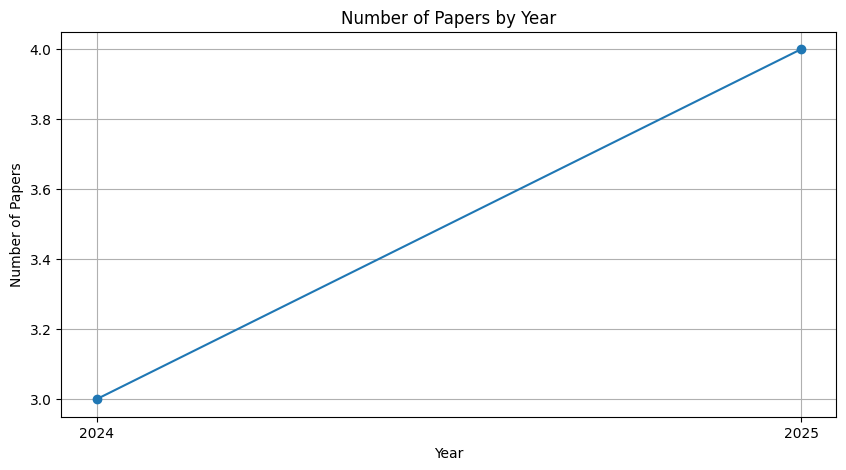

<BarContainer object of 5 artists>

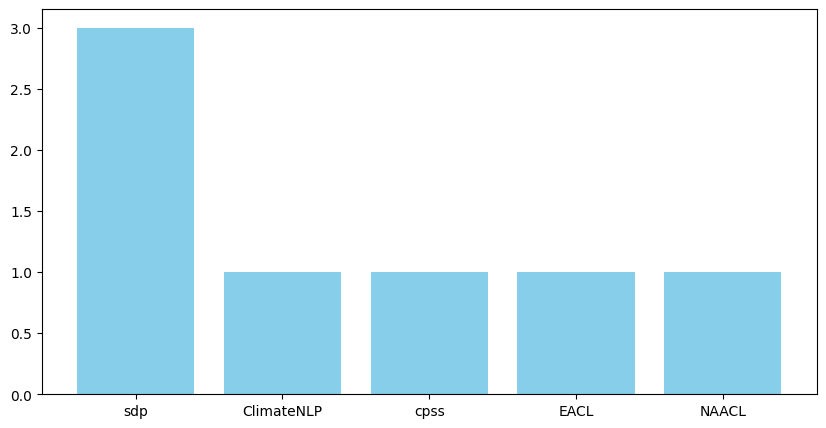

In [11]:
# Check if abstracts were collected successfully
# Load the main dataset and check abstract lengths
abstracts_with_content = 0
abstracts_empty = 0

# Collect years and venues
years = []
venues = []

f = open("../data/raw/acl/acl_data.jsonl", "r")
for line in f:
    paper = json.loads(line)
    abstract = paper.get("abstract", "")
    if abstract and len(abstract) > 0:
        abstracts_with_content += 1
    else:
        abstracts_empty += 1
    
    # Collect year 
    year = paper.get("year")
    if year:
        years.append(year)

    venue = paper.get("venue_acronym")
    if venue:
        venues.append(venue)

print(f"Papers with abstracts: {abstracts_with_content}")
print(f"Papers without abstracts: {abstracts_empty}")
print(f"Percentage of papers with abstracts: {abstracts_with_content / (abstracts_with_content + abstracts_empty) * 100:.2f}%")
print(f"Total papers: {abstracts_with_content + abstracts_empty}")

# Create a line chart for number of papers by year
year_counts = Counter(years)
sorted_years = sorted(year_counts.keys())
counts = [year_counts[year] for year in sorted_years]

plt.figure(figsize=(10, 5))
plt.plot(sorted_years, counts, marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Number of Papers by Year')
plt.grid(True)
plt.show()

# Create a bar chart for number of papers by venue
venue_counts = Counter(venues)
sorted_venues = sorted(venue_counts.keys(), key=lambda v: venue_counts[v], reverse=True)
counts = [venue_counts[venue] for venue in sorted_venues]
plt.figure(figsize=(10, 5))
plt.bar(sorted_venues, counts, color='skyblue')



## Collect data from sets and their intersections

In [12]:
# Uncomment the following code to run the data collection for all combinations of topics. Note that this will take a long time. 

sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]
all_combinations = list(chain.from_iterable(combinations(sets, r) for r in range(1, len(sets) + 1)))

# Dictionary to store the results
intersections_totals = {}

for combination in all_combinations:

    # Logic
    logic = " AND ".join(combination)
    print(f"Retrieving data for: {logic}")

    #Name for the file
    file_name = "_".join(logic.split(" "))
    
    # Extract data
    total_matched, total_scanned = collect_acl_data(
        logic_string=logic,
        keywords_path="../data/search_query/keywords.yml",
        output_path=f"../data/raw/acl/sets/{file_name}.jsonl",
        date_start=config["search"]["date_start"],
        date_end=config["search"]["date_end"],
        fields=config["acl"]["fields_lite"]
    )

    # Store the total number of results for this combination
    intersections_totals[logic] = {"total_downloaded": total_matched}

# Save the totals to a JSON file
with open("../data/raw/acl/sets/intersections_totals.json", "w") as f:
    json.dump(intersections_totals, f, indent=2)

Retrieving data for: climate
2010 2026
Logic: climate
Year range: 2010–2026
Output: ../data/raw/acl/sets/climate.jsonl
Scanned 10,000 | matched 0
Scanned 20,000 | matched 5


Unknown TeX-math command: \choose


Scanned 30,000 | matched 18
Scanned 40,000 | matched 27
Scanned 50,000 | matched 59


Unknown TeX-math command: \textcolor{red}{100~trillion}
Unknown TeX-math command: \binom{62}{6}
Unknown TeX-math command: \textcolor{red}{WARNING: This paper contains examples of harmful or inappropriate images generated by models.}


Scanned 60,000 | matched 84


Unknown TeX-math command: \DALI
Unknown TeX-math command: \mathbb{E}[X]


... (177 outputs left out)

Unknown TeX-math command: \textcolor{red}{100~trillion}
Unknown TeX-math command: \binom{62}{6}
Unknown TeX-math command: \textcolor{red}{WARNING: This paper contains examples of harmful or inappropriate images generated by models.}


Scanned 60,000 | matched 0


Unknown TeX-math command: \DALI
Unknown TeX-math command: \mathbb{E}[X]


Scanned 70,000 | matched 0
Scanned 80,000 | matched 0
Scanned 90,000 | matched 0
Scanned 100,000 | matched 0
Scanned 110,000 | matched 0
Scanned 120,000 | matched 0
Done — 0 papers matched out of 122,137 scanned. Saved to ../data/raw/acl/sets/climate_AND_nlp_AND_social_media_AND_misinformation_AND_polarization.jsonl



In [13]:
#Load the totals from the JSON file
with open("../data/raw/acl/sets/intersections_totals.json", "r") as f:
    intersections_totals = json.load(f)

In [14]:
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]

# Colors for each set
colors = {
    "climate": "green",
    "nlp": "blue",
    "social_media": "yellow",
    "misinformation": "red",
    "polarization": "gray"
}

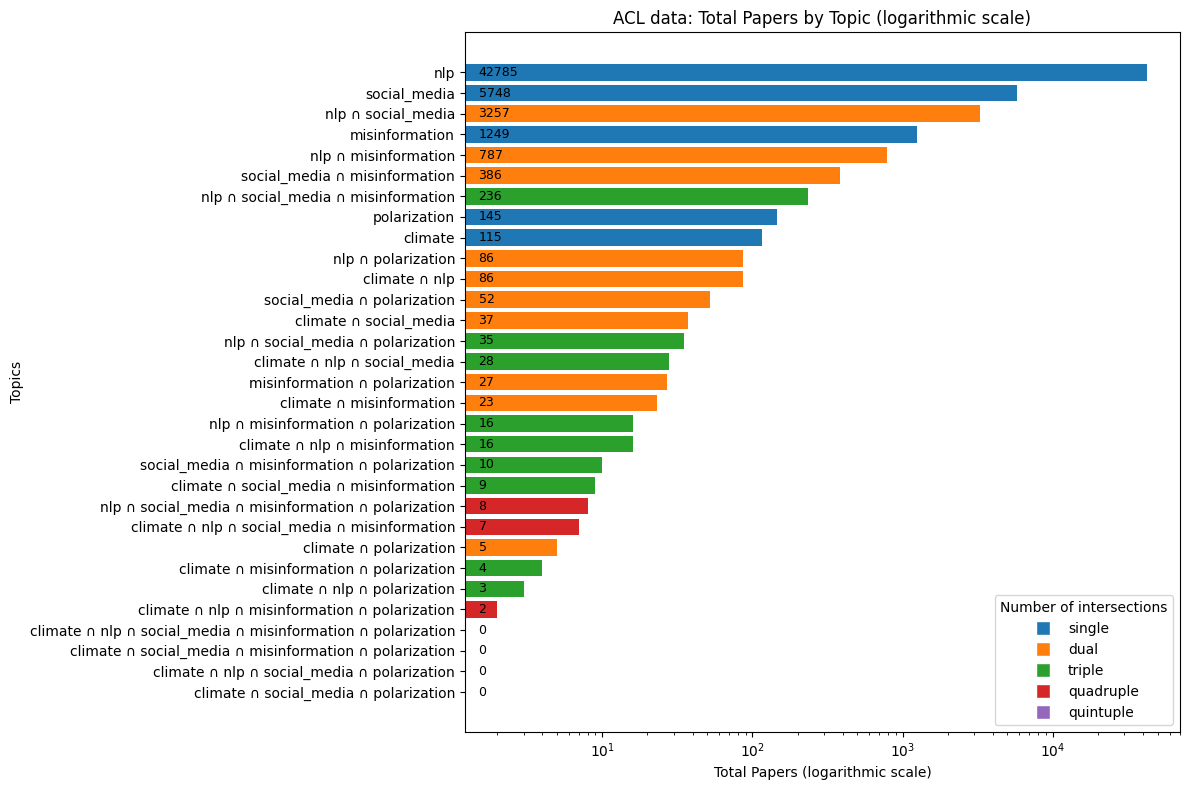

In [23]:
# See totals for each topic and their intersections

topics = list(intersections_totals.keys())
grand_totals = [intersections_totals[topic]['total_downloaded'] for topic in topics]

# Sort by grand_total ascending for better readability
sorted_indices = sorted(range(len(grand_totals)), key=lambda i: grand_totals[i], reverse=False)
topics_sorted = [topics[i] for i in sorted_indices]
grand_totals_sorted = [grand_totals[i] for i in sorted_indices]

# Map number of ANDs to label and color
level_labels = {
    0: "single",
    1: "dual",
    2: "triple",
    3: "quadruple",
    4: "quintuple",
}
color_map = {
    "single": "tab:blue",
    "dual": "tab:orange",
    "triple": "tab:green",
    "quadruple": "tab:red",
    "quintuple": "tab:purple",
}

bar_colors = []
for topic in topics_sorted:
    n_and = topic.count(" AND ")
    level = level_labels.get(n_and, f"{n_and+1}-set")
    bar_colors.append(color_map.get(level, "tab:gray"))

# Replace "AND" with intersection symbol
topics_sorted = [topic.replace(" AND ", " ∩ ") for topic in topics_sorted]

plt.figure(figsize=(12, 8))
bars = plt.barh(topics_sorted, grand_totals_sorted, color=bar_colors)
plt.xlabel('Total Papers (logarithmic scale)')
plt.ylabel('Topics')
plt.title('ACL data: Total Papers by Topic (logarithmic scale)')
plt.xscale('log')

# Add grand total numbers on the bars
for i, bar in enumerate(bars):
    plt.text(min(grand_totals)+1.5, bar.get_y() + bar.get_height() / 2,
             f'{grand_totals_sorted[i]}', va='center', fontsize=9)

# Add a legend for the bar color mapping
legend_handles = [
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=color, markersize=10, label=label)
    for label, color in color_map.items()
]
plt.legend(handles=legend_handles, title="Number of intersections", loc='lower right')

plt.tight_layout()
plt.show()

[('climate', 'nlp', 'social_media'), ('climate', 'nlp', 'misinformation'), ('climate', 'nlp', 'polarization'), ('climate', 'social_media', 'misinformation'), ('climate', 'social_media', 'polarization'), ('climate', 'misinformation', 'polarization'), ('nlp', 'social_media', 'misinformation'), ('nlp', 'social_media', 'polarization'), ('nlp', 'misinformation', 'polarization'), ('social_media', 'misinformation', 'polarization')]


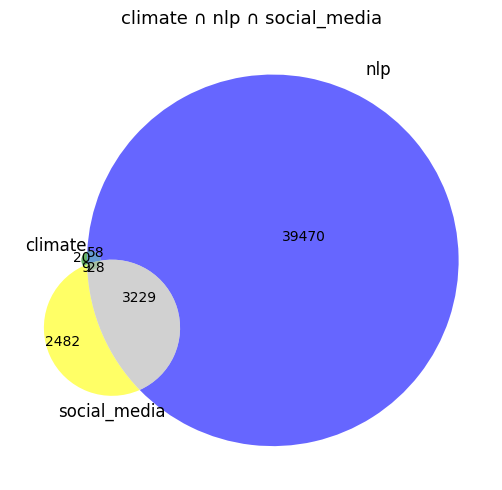

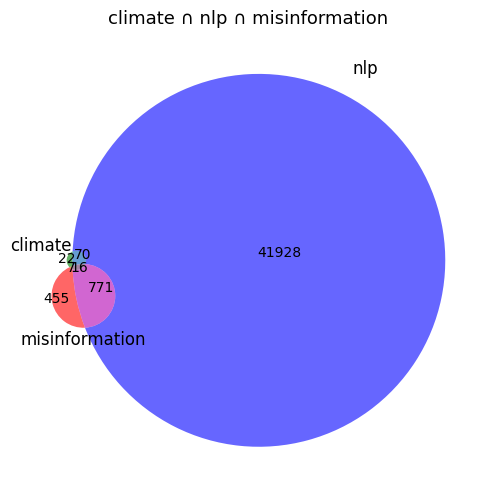

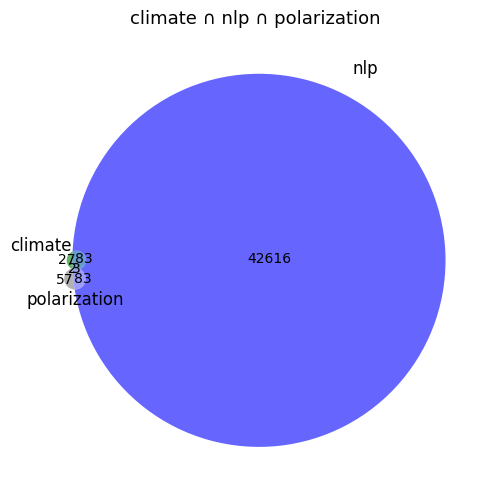

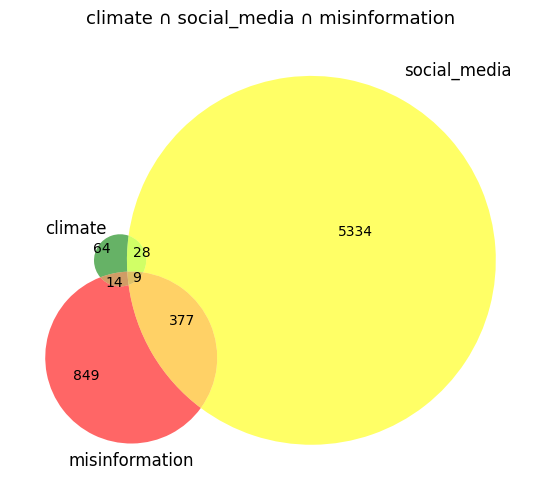

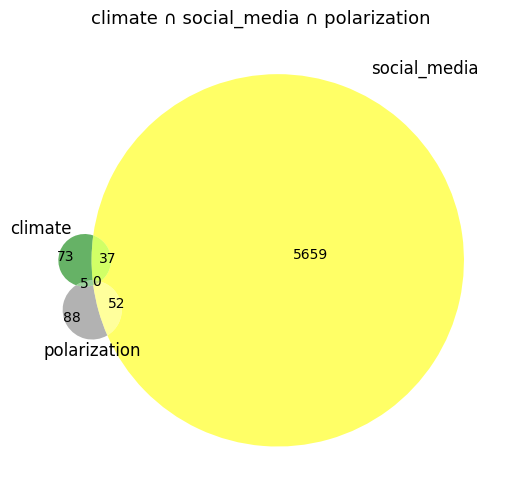

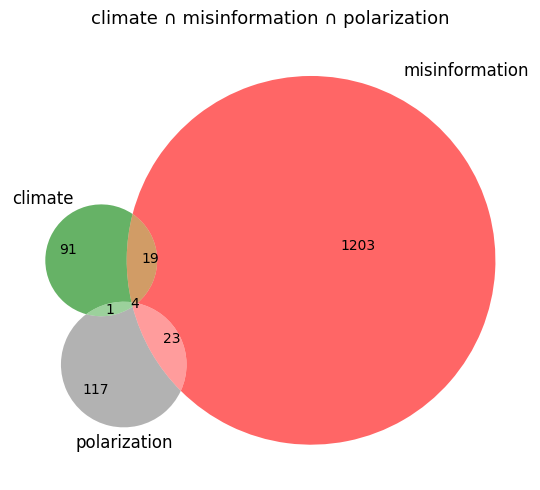

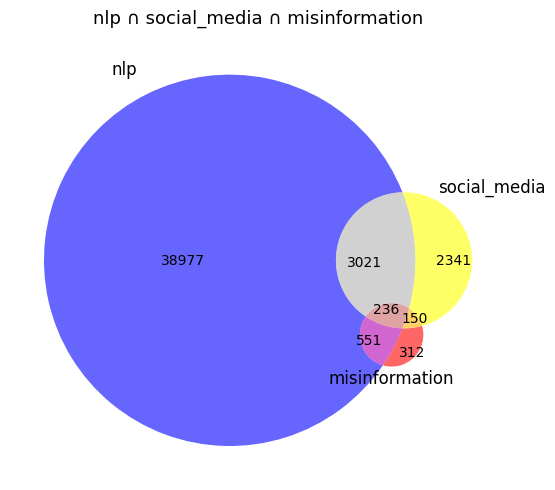

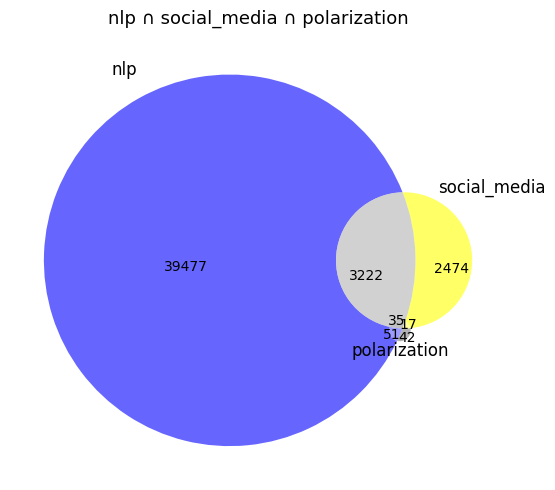

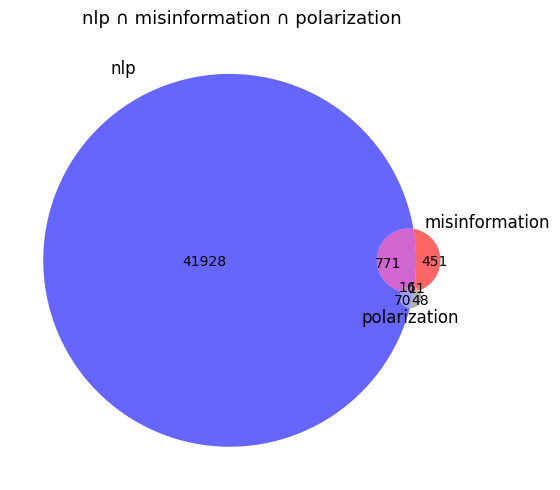

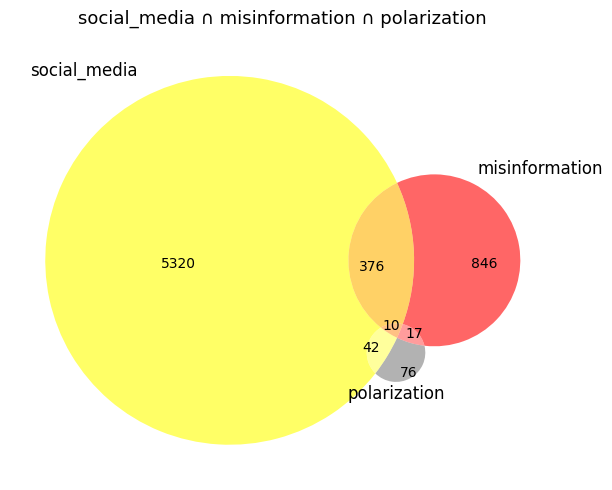

In [27]:
# Get all combinations of 3 sets
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]
combinations_of_3_sets = list(combinations(sets, 3))

# Draw Venn diagrams for all combinations of 3 sets
for sets in combinations_of_3_sets:
    venn_from_topics(
        topics=sets,
        colors=colors,
        sizes={topic: intersections_totals[topic]["total_downloaded"] for topic in intersections_totals}
    )

(<Figure size 1800x2000 with 20 Axes>,
 array([[<Axes: title={'center': 'climate ∩ nlp'}>,
         <Axes: title={'center': 'climate ∩ social_media'}>,
         <Axes: title={'center': 'climate ∩ misinformation'}>,
         <Axes: title={'center': 'climate ∩ polarization'}>],
        [<Axes: >, <Axes: title={'center': 'nlp ∩ social_media'}>,
         <Axes: title={'center': 'nlp ∩ misinformation'}>,
         <Axes: title={'center': 'nlp ∩ polarization'}>],
        [<Axes: >, <Axes: >,
         <Axes: title={'center': 'social_media ∩ misinformation'}>,
         <Axes: title={'center': 'social_media ∩ polarization'}>],
        [<Axes: >, <Axes: >, <Axes: >,
         <Axes: title={'center': 'misinformation ∩ polarization'}>],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

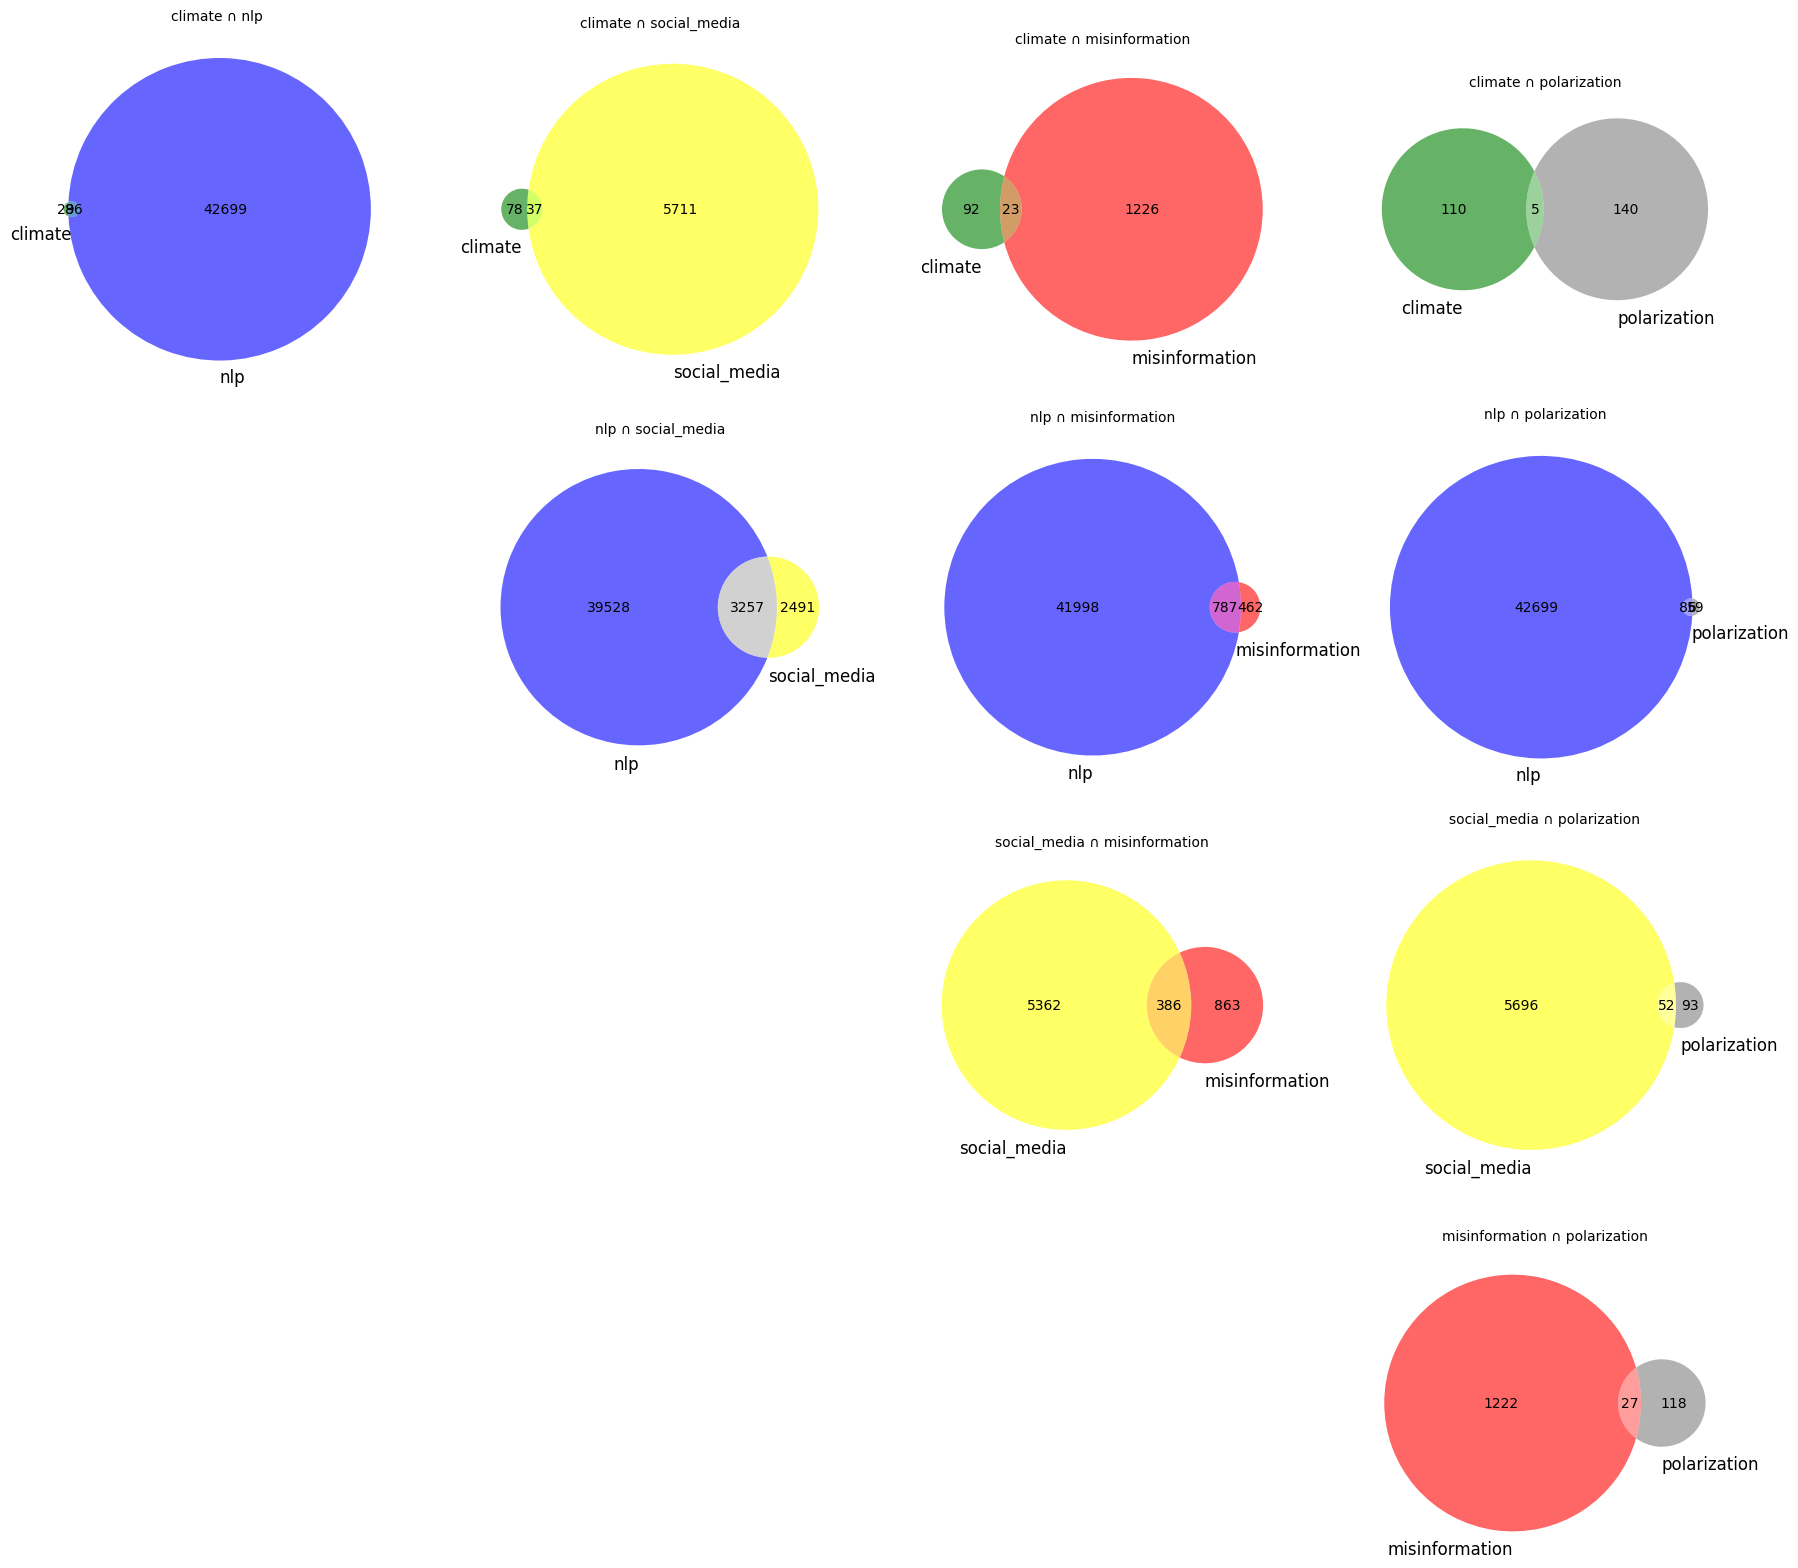

In [30]:
sets = ["climate", "nlp", "social_media", "misinformation", "polarization"]
venn_matrix(
    topics=sets,
    colors=colors,
    sizes={topic: intersections_totals[topic]["total_downloaded"] for topic in intersections_totals}
)